https://colab.research.google.com/drive/1-9NBKe1qTV8Ppxzdhzo-w2ers27oQ9Md?usp=sharing

In [3]:
%pip install "datasets==3.6.0"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 491.5/491.5 kB 11.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 116.3/116.3 kB 9.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 193.6/193.6 kB 8.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 146.7/146.7 kB 11.4 MB/s eta 0:00:00
  Attempting uninstall: fsspec
    Found existing installation: fsspec 2025.12.0
    Uninstalling fsspec-2025.12.0:
      Successfully uninstalled fsspec-2025.12.0
  Attempting uninstall: dill
    Found existing installation: dill 0.4.1
    Uninstalling dill-0.4.1:
      Successfully uninstalled dill-0.4.1
  Attempting uninstall: multiprocess
    Found existing installation: multiprocess 0.70.19
    Uninstalling multiprocess-0.70.19:
      Successfully uninstalled multiprocess-0.70.19
  Attempting uninstall: datasets
    Found existing installation: datasets 4.8.5
    Uninstalling datasets-4.8.5:
      Successfully uninstalled datasets-4.8.5
ERROR: pip's dependency reso

In [1]:
from datasets import load_dataset

We will use the `bookcorpus` dataset to train a tokenizer. It may take about
15 minutes or more to download and generate the split for the first time.

It requires approximately 5 GB of memory to load the dataset. Please ensure
you have sufficient memory available. If not, consider loading only a fraction
of the dataset.

In [3]:
ds=load_dataset("bookcorpus/bookcorpus",split="all")


README.md:   0%|          | 0.00/18.5k [00:00<?, ?B/s]

bookcorpus.py:   0%|          | 0.00/3.25k [00:00<?, ?B/s]

The repository for bookcorpus/bookcorpus contains custom code which must be executed to correctly load the dataset. You can inspect the repository content at https://hf.co/datasets/bookcorpus/bookcorpus.
You can avoid this prompt in future by passing the argument `trust_remote_code=True`.

Do you wish to run the custom code? [y/N] y


Generating train split:   0%|          | 0/74004228 [00:00<?, ? examples/s]

NameError: name 'pprint' is not defined

In [4]:
from pprint import pprint
pprint(ds)

Dataset({
    features: ['text'],
    num_rows: 74004228
})


The dataset contains 74 million sentences of varying lengths.

The length of sentences does not affect the training of a tokenizer.

Let's take a look at a few examples from the dataset.

In [5]:
num_samples=6
for idx,sample in enumerate(ds[0:num_samples]['text']):
    print(f'{idx} : {sample}')

0 : usually , he would be tearing around the living room , playing with his toys .
1 : but just one look at a minion sent him practically catatonic .
2 : that had been megan 's plan when she got him dressed earlier .
3 : he 'd seen the movie almost by mistake , considering he was a little young for the pg cartoon , but with older cousins , along with her brothers , mason was often exposed to things that were older .
4 : she liked to think being surrounded by adults and older kids was one reason why he was a such a good talker for his age .
5 : `` are n't you being a good boy ? ''


## Tokenization
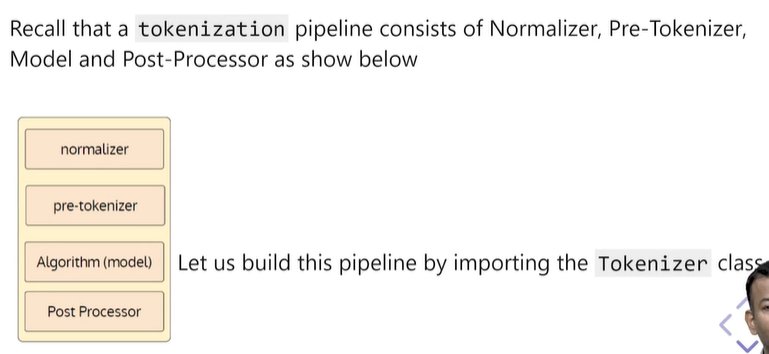

In [7]:
from tokenizers.normalizers import Lowercase
from tokenizers.pre_tokenizers import Whitespace
from tokenizers.models import BPE
from tokenizers import Tokenizer

Initiate the tokenizer with the BPE model and the special tokens ("[UNK]" in
this case) that the model will use during prediction

In [8]:
model=BPE(unk_token="[UNK]")
tokenizer=Tokenizer(model)

Add normalizer and pre-tokenizer to the pipeline


In [9]:
tokenizer.normalizer=Lowercase()
tokenizer.pre_tokenizer=Whitespace()


Create a trainer by setting `vocab_size` and `special_tokens`

In [10]:
from tokenizers.trainers import BpeTrainer
trainer=BpeTrainer(vocab_size=32000,special_tokens=["[PAD]","[UNK]"],continuing_subword_prefix="##")

The pipeline is ready. Next,we need to pass list of strings as input to the
tokenizer

However, creating an additional list containing all 74 million samples will
require an extra 5 GB of memory.

To reduce the memory usage, let us create a generator that returns a batch of
samples as a list



In [11]:
def get_examples(batch_size=1000):
    for i in range(0,len(ds),batch_size):
        yield ds[i:i+batch_size]['text']

Let us train the tokenizer

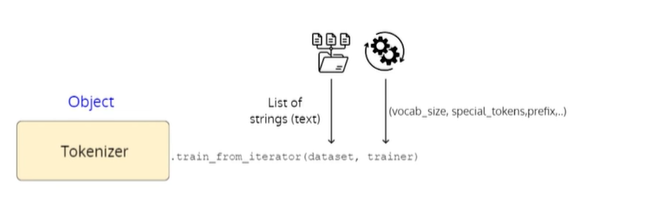

In [12]:
from multiprocessing import cpu_count
print(cpu_count())


2


In [13]:
tokenizer.train_from_iterator(get_examples(batch_size=10000),trainer=trainer,length=len(ds))

The training took about 5 minutes to complete and required an additional 1
GB of memory.

It would be interesting to see the subtokens that were merged to create the
final vocabulary.

In [17]:
tokenizer.model.save("model",prefix="hopper")

['model/hopper-vocab.json', 'model/hopper-merges.txt']

In [18]:
with open("model/hopper-merges.txt","r") as file:
    row=0
    num_lines=10
    for line in file.readlines():
        print(line)
        row+=1
        if row>=num_lines:
            break


#version: 0.2

##h ##e

t ##he

##i ##n

##e ##r

##e ##d

##o ##u

##n ##d

##in ##g

t ##o



- Display last `n` merges

In [19]:
with open("model/hopper-merges.txt","r") as file:
    row=0
    num_lines=10
    for line in reversed(file.readlines()):
        print(line)
        row+=1
        if row>=num_lines:
            break

mel ##anthe

black ##er

ad ##ject

v ##ang

betroth ##al

tiptoe ##ing

restroom ##s

consol ##ing

esp ##ionage

influ ##x



## Vocabulary


In [20]:
# lets view the number of merges
with open("model/hopper-merges.txt",'r') as file:
    lines=file.readlines()


In [21]:
print(f"Number of merges: {len(lines)}")

Number of merges: 31871


In [22]:
print(f"vocab size: {tokenizer.get_vocab_size()}")

vocab size: 32000


The number of merges is slightly less than the size of the vocabulary because
the merges do not include single-character tokens, such as letters, numbers
and special symbols.

We can view the final learned vocabulary either from the saved hopper-
vocab. json file or by using the get_vocab method.

In [23]:
vocab=tokenizer.get_vocab()

For convenience, let's print the vocabulary sorted by token ID's

In [24]:
vocab_sorted=sorted(vocab.items(),key=lambda item:item[1])

Let's adjust the sliders below to view the merged subwords and their
corresponding tokens in the vocabulary.

In [ ]:

# _= interact(get_pairs,pair=widgets.IntSlider(min=1, max=len(lines)-1, step=1,
# value=1, layout=Layout(width='900px')))
# 2 _ = interact(display_token_id,id=widgets.IntSlider(min=0, max=31999, step=1,
# value=130,layout=Layout(width='900px')))

Note that the 130th ID represents the first merge. What will the next two
tokens to be merged be? You can explore this by moving the sliders.

The sub-words are `t` and `##he`. After the merge, they will form the token
`the`.

# L9: Encdode & decoder | tokenization explained with BERT, padding & truncation


Pass a single sample to the encode method of the tokenizer class

In [25]:
sample=ds[0]['text']
print(f'sample: {sample}')
encoding=tokenizer.encode(sample)
print(encoding)

sample: usually , he would be tearing around the living room , playing with his toys .
Encoding(num_tokens=16, attributes=[ids, type_ids, tokens, offsets, attention_mask, special_tokens_mask, overflowing])


It returned the output as `Encoding` object that contains useful attributes
such as `token_ids` (ids), `type_ids` and so on

we need to access these attributes to get their respective values

In [26]:
token_ids=encoding.ids
tokens=encoding.tokens
type_ids=encoding.type_ids
attention_mask=encoding.attention_mask

In [27]:
from tokenizers.tools import EncodingVisualizer
visualizer = EncodingVisualizer(tokenizer=tokenizer)
visualizer(text=sample)

In [28]:
import pandas as pd
out_dict={'tokens':tokens,'ids':token_ids,'type_ids':type_ids,'attention_mask':attention_mask}
df=pd.DataFrame.from_dict(out_dict)
df

,tokens,ids,type_ids,attention_mask
0,usually,2462,0,1
1,",",19,0,1
2,he,149,0,1
3,would,277,0,1
4,be,162,0,1
5,tearing,6456,0,1
6,around,422,0,1
7,the,131,0,1
8,living,1559,0,1
9,room,536,0,1


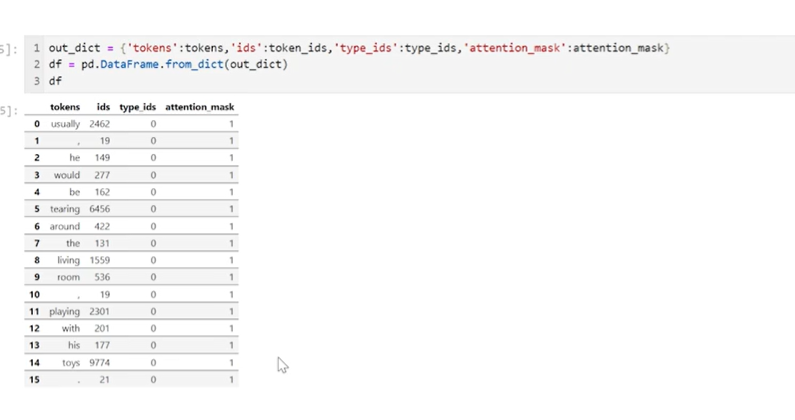

`attention_mask=1` because , when we pass this to the model after tokenization, sometimes we need to pass this mask

`type_ids` are model-specific. For instance, BERT-like models use type IDs of
0 and 1.

- what is `[PAD]`
- in a give batch we might have sentences of varying length.
- we might want to make sure that entire batch looks like a matrix,
- number of rows= no of sentences in a batch
- but no.of columns will be different.


## Batch Encoding
When encoding a batch of samples, we need to [PAD] shorter sequences in
the batch, a process known as dynamic batching.

Therefore, we use encode_batch method of the tokenizer object.

The token_id for the [PAD] token is 0

In [29]:
samples=ds[0:4]['text']


In [30]:
batch_encoding=tokenizer.encode_batch(samples)
pprint(batch_encoding)

[Encoding(num_tokens=16, attributes=[ids, type_ids, tokens, offsets, attention_mask, special_tokens_mask, overflowing]),
 Encoding(num_tokens=14, attributes=[ids, type_ids, tokens, offsets, attention_mask, special_tokens_mask, overflowing]),
 Encoding(num_tokens=14, attributes=[ids, type_ids, tokens, offsets, attention_mask, special_tokens_mask, overflowing]),
 Encoding(num_tokens=42, attributes=[ids, type_ids, tokens, offsets, attention_mask, special_tokens_mask, overflowing])]


The maximum length of the sequence in the batch is 42. Clearly, padding is
not applied to the remaining samples.

In general, it is also possible for the length of a sequence to exceed the
model's context length (or window size).

Assuming the model's context length is 512, enable padding and truncation
while batching the samples.

In [33]:
# all default args
tokenizer.enable_padding(direction="right",
                         pad_id=0,
                         pad_type_id=0,
                         pad_token='[PAD]',
                         length=None,
                         pad_to_multiple_of=None)

tokenizer.enable_truncation(max_length=512) # anything above 512 we will leave it

In [34]:
batch_encoding=tokenizer.encode_batch(samples)
pprint(batch_encoding)

[Encoding(num_tokens=42, attributes=[ids, type_ids, tokens, offsets, attention_mask, special_tokens_mask, overflowing]),
 Encoding(num_tokens=42, attributes=[ids, type_ids, tokens, offsets, attention_mask, special_tokens_mask, overflowing]),
 Encoding(num_tokens=42, attributes=[ids, type_ids, tokens, offsets, attention_mask, special_tokens_mask, overflowing]),
 Encoding(num_tokens=42, attributes=[ids, type_ids, tokens, offsets, attention_mask, special_tokens_mask, overflowing])]


Now we can see that all samples in the batch are of the same length.

# Quick test
Let's pass a test sequence that contains two tokens not present in the vocabulary

In [35]:
text = "All this is so simple to do in HF இ😊."
encoded = tokenizer.encode(text).tokens
print(encoded)

['all', 'this', 'is', 'so', 'simple', 'to', 'do', 'in', 'h', '##f', '[UNK]', '[UNK]', '##.']


Normalization worked as expected (This -> this, HF -> hf)

Pre-tokenization followed by model tokenization has been applied correctly

The continuing prefix has been used appropriately.('##f','##.')

# Saving and Loading Tokenizer

Let us save the tokenizer and load it in a single line of code in the model
training script

In [36]:
tokenizer.save('hopper.json')

It saves all the required information such as `added_tokens`, details of the
`model` (vocab,merges, .. ), `normalizer, pre-tokenizer`..


In [37]:
import json
with open("hopper.json",'r') as file:
    json_data=json.load(file)

In [38]:
pprint(json_data,depth=1)

{'added_tokens': [...],
 'decoder': None,
 'model': {...},
 'normalizer': {...},
 'padding': {...},
 'post_processor': None,
 'pre_tokenizer': {...},
 'truncation': {...},
 'version': '1.0'}


In [39]:
trained_tokenizer=Tokenizer(BPE())


In [40]:
trained_tokenizer=trained_tokenizer.from_file('hopper.json')

In [41]:
tokens=trained_tokenizer.encode(text).tokens
print(tokens)

['all', 'this', 'is', 'so', 'simple', 'to', 'do', 'in', 'h', '##f', '[UNK]', '[UNK]', '##.']


# BERT Tokenizer

Let's quickly build a BERT-like tokenizer (don't worry about what BERT-like
models are for now)

The input to BERT models generally follows the template below, with slight
variations across different BERT implementations.

[ `[CLS]`, token-A_1, ... , token-A_n, `[SEP]`, token-B_1, ... , token-B_m ]

Here A denotes sentence A with n tokens and B denotes sentence B with
tokens.

The special tokens are : `[CLS],[SEP],[PAD],[MASK] and [UNK]`

In [42]:
bert_tokenizer=Tokenizer(BPE(unk_token='[UNK]'))
bert_tokenizer.normalizer=Lowercase()
bert_tokenizer.pre_tokenizer=Whitespace()
bert_trainer=BpeTrainer(vocab_size=32000,
                        special_tokens=["[PAD]","[UNK]","[CLS]","[SEP]","[MASK]"],
                        continuing_subword_prefix="##"
                        )

We just need to add `post_processing_step` where the special tokens are
inserted according to the template

In [43]:
from tokenizers.processors import TemplateProcessing

If we pass a single sentence, the tokenizer should output `"[CLS] $0
[SEP]"` where 0 denotes the `type_id` (which defaults to zero if there is a
single sentence)

If we pass a pair of sentence, the tokenizer should output `"[CLS] $A:0
[SEP] $B:1"`

In [46]:
bert_tokenizer.post_processor=TemplateProcessing(single="[CLS] $0 [SEP]",
                                                pair="[CLS] $A [SEP] $B:1",
                                                special_tokens=[("[CLS]", 2), ("[SEP]", 3)],
                                    )

In [48]:
bert_tokenizer.train_from_iterator(get_examples(batch_size=10000),trainer=bert_trainer,length=len(ds))

In [54]:
# Pass a single sentence to the tokenizer

text = "All these are so simple to do in HF. Let's do more"
encoded = bert_tokenizer.encode(text)
tokens = encoded. tokens
ids = encoded.ids
out_dict = {'tokens':tokens, 'ids':ids}
pprint(out_dict,depth=2,compact=True)


{'ids': [2, 270, 956, 336, 231, 2534, 141, 206, 157, 56, 82, 24, 462, 17, 67,
         206, 387, 3],
 'tokens': ['[CLS]', 'all', 'these', 'are', 'so', 'simple', 'to', 'do', 'in',
            'h', '##f', '.', 'let', "'", 's', 'do', 'more', '[SEP]']}


In [49]:
text = "All these are so simple to do in HF. Let's do more"
pair="We have a long way to go!"
encoded = bert_tokenizer.encode(text,pair)
tokens = encoded. tokens
ids = encoded.ids
out_dict = {'tokens':tokens, 'ids':ids}
pprint(out_dict,depth=2,compact=True)

{'ids': [2, 270, 956, 336, 231, 2534, 141, 206, 157, 56, 82, 24, 462, 17, 67,
         206, 387, 3, 214, 250, 49, 490, 415, 141, 260, 12],
 'tokens': ['[CLS]', 'all', 'these', 'are', 'so', 'simple', 'to', 'do', 'in',
            'h', '##f', '.', 'let', "'", 's', 'do', 'more', '[SEP]', 'we',
            'have', 'a', 'long', 'way', 'to', 'go', '!']}


## Decoding

The special tokens (for ex, [PAD]) need to be removed and sub-words have
to be merged before outputting the final result to the end user.

Let us decode the enoced token_ids from the previous step.

In [50]:
plain_tokens = bert_tokenizer.decode(ids)
print(plain_tokens)

all these are so simple to do in h ##f . let ' s do more we have a long way to go !


The special tokens were removed, but the subword (h, ##f) wasn't merged
into a complete word.

We need to use appropriate decoders based on the type of tokenizer. See the
list of decoders here

In [51]:
from tokenizers.decoders import WordPiece


In [52]:
bert_tokenizer.decoder=WordPiece(prefix="##")

In [53]:
plain_tokens=bert_tokenizer.decode(ids)
print(plain_tokens)

all these are so simple to do in hf. let ' s do more we have a long way to go!


In [55]:
bert_tokenizer.model.save("model",prefix="bert")

['model/bert-vocab.json', 'model/bert-merges.txt']

In [56]:
bert_tokenizer.save('bert.json')

In [ ]:
# https://chatgpt.com/share/6ad4575d-5750-83ee-ae88-ed33e31e070d

# difference between model.save and just .save